In [1]:
import pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot

In [2]:
file_path = "https://raw.github.com/jan-source/ppa_erp_student/main/sessions/1_session/fmcg_data.xlsx"

In [3]:
data = pd.read_excel(file_path)

In [4]:
data

,Date,Product,MarketDescription_global,VolumePC_sum,isPromoPeriod,pricePerPieceNonPromo,TV,BB,DI,WeightedDistribution_max
0,2015-01-05,q1152,CASH & CARRY,115,False,4.114783,0.0,0.0,0.0,45
1,2015-01-05,q120q,CASH & CARRY,62,False,3.912903,0.0,0.0,0.0,32
2,2015-01-05,q1152,DEPARTMENT STORES,41,False,6.168293,0.0,0.0,0.0,26
3,2015-01-05,q120q,DEPARTMENT STORES,47,False,5.851064,0.0,0.0,0.0,30
4,2015-01-05,q1152,DISCOUNTER,23640,False,3.452022,0.0,0.0,0.0,48
...,...,...,...,...,...,...,...,...,...,...
5960,2018-04-30,q12q9,DEPARTMENT STORES,29,False,11.782759,0.0,0.0,0.0,21
5961,2018-04-30,q12q7,DISCOUNTER,4679,False,7.724129,0.0,0.0,0.0,20
5962,2018-04-30,q1221,DRUGSTORES,13231,True,0.951632,0.0,0.0,0.0,41
5963,2018-04-30,q12q7,DRUGSTORES,16004,True,7.411118,0.0,0.0,0.0,93


### Zeige die ersten 5 Zeilen

In [5]:
data.head()

,Date,Product,MarketDescription_global,VolumePC_sum,isPromoPeriod,pricePerPieceNonPromo,TV,BB,DI,WeightedDistribution_max
0,2015-01-05,q1152,CASH & CARRY,115,False,4.114783,0.0,0.0,0.0,45
1,2015-01-05,q120q,CASH & CARRY,62,False,3.912903,0.0,0.0,0.0,32
2,2015-01-05,q1152,DEPARTMENT STORES,41,False,6.168293,0.0,0.0,0.0,26
3,2015-01-05,q120q,DEPARTMENT STORES,47,False,5.851064,0.0,0.0,0.0,30
4,2015-01-05,q1152,DISCOUNTER,23640,False,3.452022,0.0,0.0,0.0,48


### Wähle die Spalte VolumePC_sum aus

In [6]:
data['VolumePC_sum']

0         115
1          62
2          41
3          47
4       23640
        ...  
5960       29
5961     4679
5962    13231
5963    16004
5964    19472
Name: VolumePC_sum, Length: 5965, dtype: int64

### Wähle zwei Spalten aus

In [7]:
data[['Product', 'VolumePC_sum', 'TV']]

,Product,VolumePC_sum,TV
0,q1152,115,0.0
1,q120q,62,0.0
2,q1152,41,0.0
3,q120q,47,0.0
4,q1152,23640,0.0
...,...,...,...
5960,q12q9,29,0.0
5961,q12q7,4679,0.0
5962,q1221,13231,0.0
5963,q12q7,16004,0.0


### Wähle erste Zeile aus

In [8]:
data.iloc[0]

Date                        2015-01-05 00:00:00
Product                                   q1152
MarketDescription_global           CASH & CARRY
VolumePC_sum                                115
isPromoPeriod                             False
pricePerPieceNonPromo                  4.114783
TV                                          0.0
BB                                          0.0
DI                                          0.0
WeightedDistribution_max                     45
Name: 0, dtype: object

### Wähle die ersten beiden Zeilen aus

In [9]:
data.iloc[0:2]

,Date,Product,MarketDescription_global,VolumePC_sum,isPromoPeriod,pricePerPieceNonPromo,TV,BB,DI,WeightedDistribution_max
0,2015-01-05,q1152,CASH & CARRY,115,False,4.114783,0.0,0.0,0.0,45
1,2015-01-05,q120q,CASH & CARRY,62,False,3.912903,0.0,0.0,0.0,32


### von den ersten beiden Zeilen, die Spalten VolumePC_sum, TV auswählen

In [10]:
data.iloc[0:2][["VolumePC_sum", "TV"]]

,VolumePC_sum,TV
0,115,0.0
1,62,0.0


### Selektiere alle Zeilen in den VolumePC_sum > 100

In [11]:
data[data["VolumePC_sum"] > 100]

,Date,Product,MarketDescription_global,VolumePC_sum,isPromoPeriod,pricePerPieceNonPromo,TV,BB,DI,WeightedDistribution_max
0,2015-01-05,q1152,CASH & CARRY,115,False,4.114783,0.0,0.0,0.0,45
4,2015-01-05,q1152,DISCOUNTER,23640,False,3.452022,0.0,0.0,0.0,48
5,2015-01-05,q120q,DISCOUNTER,16527,False,3.452072,0.0,0.0,0.0,40
6,2015-01-05,q1152,DRUGSTORES,15553,True,3.440518,0.0,0.0,0.0,95
7,2015-01-05,q120q,DRUGSTORES,13697,True,3.451025,0.0,0.0,0.0,94
...,...,...,...,...,...,...,...,...,...,...
5958,2018-04-30,q12q9,CASH & CARRY,107,False,10.406542,0.0,0.0,0.0,63
5961,2018-04-30,q12q7,DISCOUNTER,4679,False,7.724129,0.0,0.0,0.0,20
5962,2018-04-30,q1221,DRUGSTORES,13231,True,0.951632,0.0,0.0,0.0,41
5963,2018-04-30,q12q7,DRUGSTORES,16004,True,7.411118,0.0,0.0,0.0,93


### Selektiere Zeilen in denen das Verkaufsvolumen exakt 100 ist

In [12]:
data[data['VolumePC_sum'] == 100]

,Date,Product,MarketDescription_global,VolumePC_sum,isPromoPeriod,pricePerPieceNonPromo,TV,BB,DI,WeightedDistribution_max
805,2015-06-22,q1906,DEPARTMENT STORES,100,True,3.426531,0.00,0.000,0.000,37
820,2015-06-29,q120q,CASH & CARRY,100,True,3.881522,0.00,0.000,0.000,46
1146,2015-09-07,q1100,CASH & CARRY,100,True,3.659596,0.00,0.000,0.000,55
1659,2016-01-04,q1152,CASH & CARRY,100,True,3.945055,0.00,0.000,0.000,54
2142,2016-04-18,q1106,CASH & CARRY,100,True,4.056250,216487.47,37306.612,0.000,44
2215,2016-05-02,q1100,CASH & CARRY,100,True,4.094286,0.00,33405.190,9248.907,40
2763,2016-08-15,q1152,CASH & CARRY,100,True,3.914583,0.00,0.000,0.000,54
3127,2016-10-24,q120q,CASH & CARRY,100,True,3.880612,0.00,0.000,0.000,48
3511,2017-01-02,q1906,HYPERMARKETS,100,False,1.683000,0.00,0.000,0.000,1
3841,2017-03-13,q1152,CASH & CARRY,100,True,3.901695,0.00,0.000,0.000,47


### Selektiere Zeilen in denen das verkaufte Volumen größer als 200 ist und der Verkaufspreise größer 4

In [13]:
data[(data['VolumePC_sum'] > 200) & (data['pricePerPieceNonPromo'] > 4)]

,Date,Product,MarketDescription_global,VolumePC_sum,isPromoPeriod,pricePerPieceNonPromo,TV,BB,DI,WeightedDistribution_max
24,2015-01-05,q12q7,CASH & CARRY,246,False,9.187398,99830.65,0.0,0.0,55
25,2015-01-05,q12q9,CASH & CARRY,232,True,10.649444,99830.65,0.0,0.0,52
28,2015-01-05,q12q7,DISCOUNTER,12265,False,9.928830,99830.65,0.0,0.0,14
29,2015-01-05,q12q9,DISCOUNTER,12200,False,9.907148,99830.65,0.0,0.0,14
30,2015-01-05,q12q7,DRUGSTORES,10367,True,9.835501,99830.65,0.0,0.0,90
...,...,...,...,...,...,...,...,...,...,...
5927,2018-04-23,q12q7,DRUGSTORES,11391,True,7.358731,0.00,0.0,0.0,89
5928,2018-04-23,q12q9,DRUGSTORES,12382,True,8.309773,0.00,0.0,0.0,91
5961,2018-04-30,q12q7,DISCOUNTER,4679,False,7.724129,0.00,0.0,0.0,20
5963,2018-04-30,q12q7,DRUGSTORES,16004,True,7.411118,0.00,0.0,0.0,93


### Wie viele unterschiedliche Produkte gibt es

In [14]:
data['Product'].unique()

<StringArray>
['q1152', 'q120q', 'q1100', 'q1106', 'q1110', 'q1906', 'q12q7', 'q12q9',
 'q1221', 'q9232']
Length: 10, dtype: str

In [15]:
len(data['Product'].unique())

10

### Absatzvolumen pro Produkt

In [16]:
data.groupby('Product')['VolumePC_sum'].sum()

Product
q1100    3369891
q1106    2842309
q1110    1871227
q1152    4798657
q120q    5093518
q1221    1801660
q12q7    2223063
q12q9    2656715
q1906    4856252
q9232    3216284
Name: VolumePC_sum, dtype: int64

### Absatzvolumen nach Absatzkanal

In [17]:
data.groupby('MarketDescription_global')['VolumePC_sum'].sum()

MarketDescription_global
CASH & CARRY           373767
DEPARTMENT STORES       61149
DISCOUNTER            6689871
DRUGSTORES           22706392
HYPERMARKETS          2856892
SUPERMARKETS            41505
Name: VolumePC_sum, dtype: int64

### Absatzvolumen pro Product/Kanal Kombination

In [18]:
data.groupby(['Product','MarketDescription_global'])['VolumePC_sum'].sum()

Product  MarketDescription_global
q1100    CASH & CARRY                  44407
         DEPARTMENT STORES              5151
         DISCOUNTER                   282126
         DRUGSTORES                  2432020
         HYPERMARKETS                 596335
         SUPERMARKETS                   9852
q1106    CASH & CARRY                  47799
         DEPARTMENT STORES              5351
         DISCOUNTER                   176115
         DRUGSTORES                  1977428
         HYPERMARKETS                 635616
q1110    CASH & CARRY                  69709
         DEPARTMENT STORES              7077
         DRUGSTORES                  1707610
         HYPERMARKETS                  79173
         SUPERMARKETS                   7658
q1152    CASH & CARRY                  16732
         DEPARTMENT STORES              4656
         DISCOUNTER                  2629413
         DRUGSTORES                  2147856
q120q    CASH & CARRY                  18017
         DEPARTMENT S

In [19]:
data[(data['Product'] == 'q1106') & 
     (data['MarketDescription_global'] == 'DISCOUNTER')]['VolumePC_sum'].sum()

np.int64(176115)

### Übersicht Verkaufszahlen im Channel DISCOUNTER und für das Produkt q1106

In [20]:
subset = data[(data['Product'] == 'q1106') & 
     (data['MarketDescription_global'] == 'DISCOUNTER')]

In [21]:
pyplot.rcParams['figure.figsize'] = [15, 7]

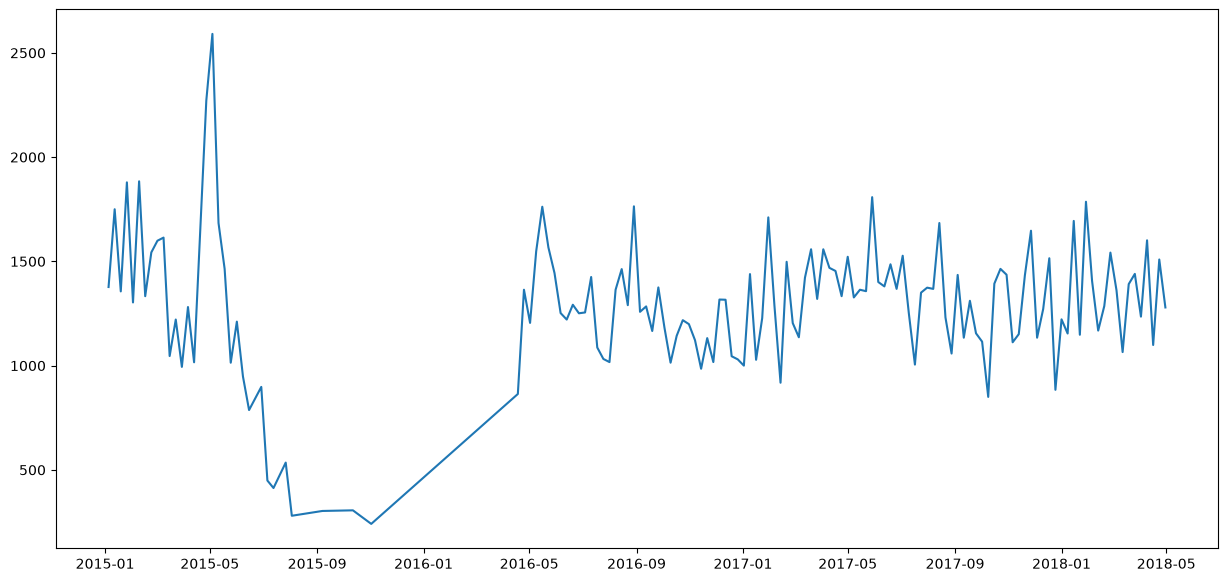

In [22]:
pyplot.plot(
    subset['Date'],
    subset['VolumePC_sum']
)

### Aggregiert Daten pro Tag über alle Produkte und Channel

<Axes: xlabel='Date'>

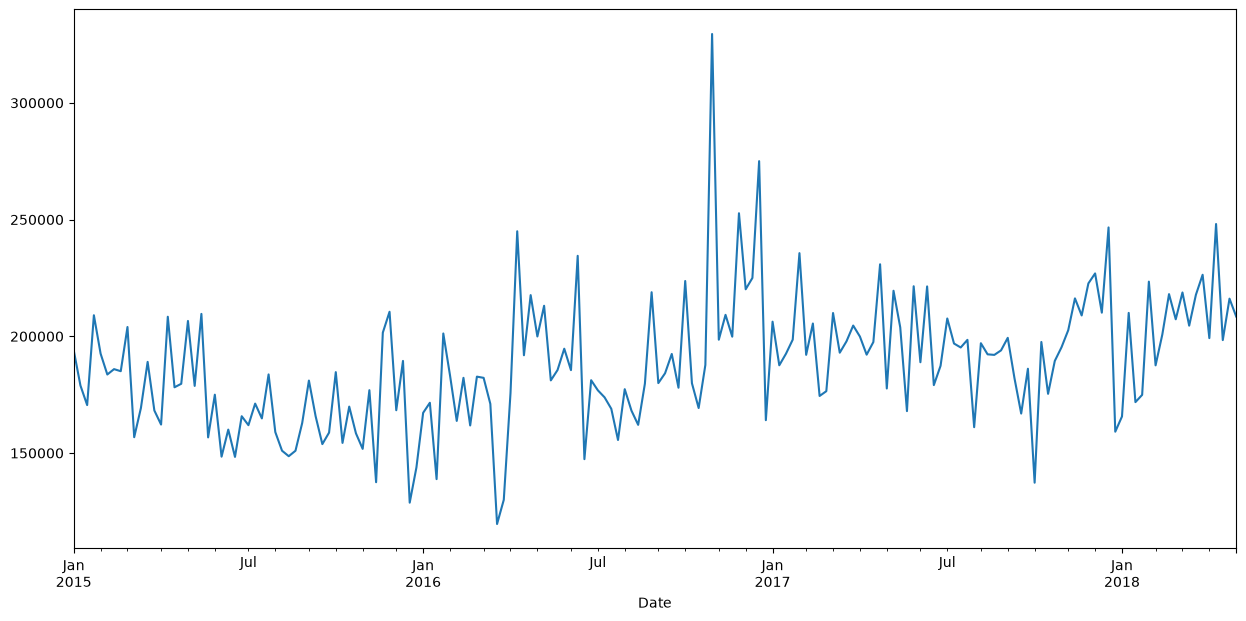

In [23]:
data.groupby('Date')['VolumePC_sum'].sum().plot()

<Axes: xlabel='MarketDescription_global,Date'>

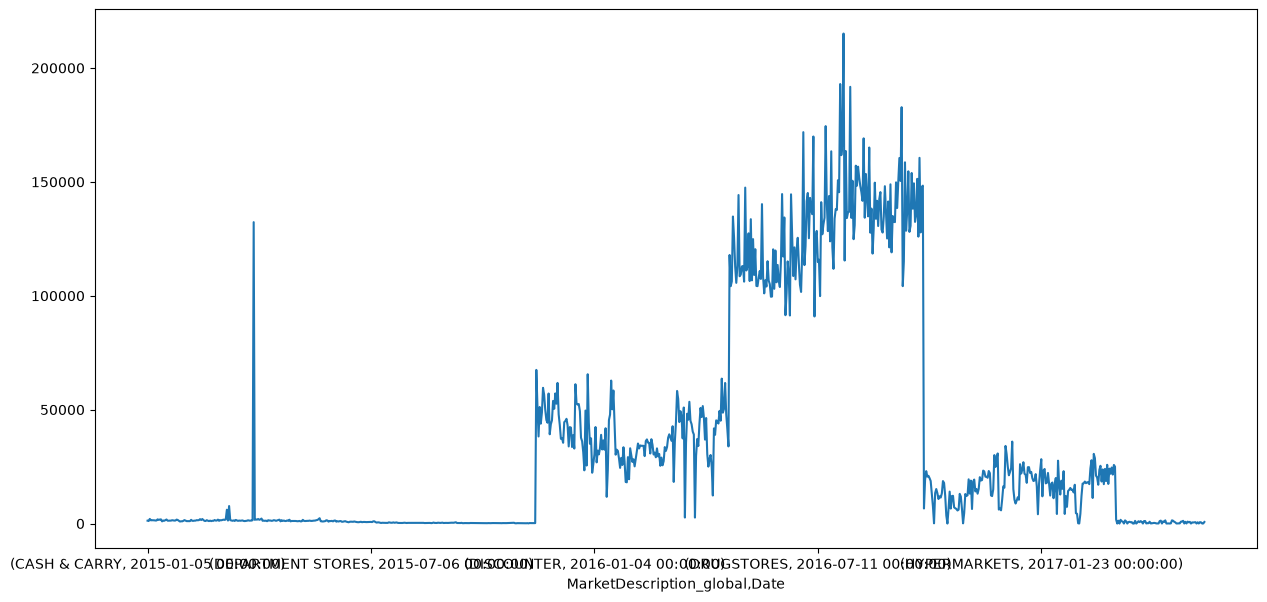

In [24]:
data.groupby(['MarketDescription_global','Date'])['VolumePC_sum'].sum().plot()

In [25]:
data.columns

Index(['Date', 'Product', 'MarketDescription_global', 'VolumePC_sum',
       'isPromoPeriod', 'pricePerPieceNonPromo', 'TV', 'BB', 'DI',
       'WeightedDistribution_max'],
      dtype='str')

### Lineare Regression Verkaufsmenge (VolumePC_sum) durch Preis (pricePerPieceNonPromo) erklären

In [26]:
import statsmodels.api as sm

### Filter Daten für Produkt (q1152) und Kanal (DRUGSTORES)

In [27]:
subset_q1152_drugstores = data[(data['Product'] == 'q1152') & (data['MarketDescription_global'] == 'DRUGSTORES')]

In [28]:
subset_q1152_drugstores.shape

(174, 10)

### Model definieren

In [29]:
mod_q1152_drugstores = sm.OLS(subset_q1152_drugstores['VolumePC_sum'], 
                              subset_q1152_drugstores['pricePerPieceNonPromo'])

### Model trainieren

In [30]:
mod_q1152_drugstores.fit()

In [31]:
mod_q1152_drugstores.fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:           VolumePC_sum   R-squared (uncentered):                   0.975
Model:                            OLS   Adj. R-squared (uncentered):              0.975
Method:                 Least Squares   F-statistic:                              6868.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):                   3.62e-141
Time:                        20:54:50   Log-Likelihood:                         -1566.0
No. Observations:                 174   AIC:                                      3134.
Df Residuals:                     173   BIC:                                      3137.
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
pricePerPieceNonPromo  3613.9591     43.609     82.873      0.000    3527.886    3700.032
==============================================================================
Omnibus:                        7.792   Durbin-Watson:                   0.508
Prob(Omnibus):                  0.020   Jarque-Bera (JB):                8.138
Skew:                           0.526   Prob(JB):                       0.0171
Kurtosis:                       2.877   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Berücksichtigung Achsenabschnitt

In [32]:
x = subset_q1152_drugstores['pricePerPieceNonPromo']

### Hinzufügen der Konstanten / Achsenabschnitt

In [33]:
x = sm.add_constant(x)

In [34]:
x

,const,pricePerPieceNonPromo
6,1.0,3.440518
38,1.0,3.428136
72,1.0,3.434770
105,1.0,3.445459
138,1.0,3.456038
...,...,...
5785,1.0,3.319952
5821,1.0,3.324410
5859,1.0,3.323242
5898,1.0,3.317069


In [35]:
mod_q1152_drugstores_with_constant = sm.OLS(subset_q1152_drugstores['VolumePC_sum'], x)

In [36]:
mod_q1152_drugstores_with_constant.fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           VolumePC_sum   R-squared:                       0.196
Model:                            OLS   Adj. R-squared:                  0.192
Method:                 Least Squares   F-statistic:                     42.03
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           9.17e-10
Time:                        20:54:50   Log-Likelihood:                -1551.0
No. Observations:                 174   AIC:                             3106.
Df Residuals:                     172   BIC:                             3112.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                  -8.82e+04   1.55e+04     -5.687      0.000   -1.19e+05   -5.76e+04
pricePerPieceNonPromo  2.942e+04   4538.141      6.483      0.000    2.05e+04    3.84e+04
==============================================================================
Omnibus:                        1.315   Durbin-Watson:                   0.683
Prob(Omnibus):                  0.518   Jarque-Bera (JB):                1.146
Skew:                           0.198   Prob(JB):                        0.564
Kurtosis:                       3.023   Cond. No.                         420.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### Model mit zusätzlichen Variablen:  'isPromoPeriod',  'TV', 'BB', 'DI'

In [37]:
x = subset_q1152_drugstores[['pricePerPieceNonPromo', 'isPromoPeriod', 'TV', 'BB', 'DI']]

In [38]:
x = sm.add_constant(x)

In [39]:
x

,const,pricePerPieceNonPromo,isPromoPeriod,TV,BB,DI
6,1.0,3.440518,True,0.0,0.0,0.00
38,1.0,3.428136,True,0.0,0.0,0.00
72,1.0,3.434770,True,0.0,0.0,0.00
105,1.0,3.445459,True,0.0,0.0,0.00
138,1.0,3.456038,True,0.0,0.0,1714.02
...,...,...,...,...,...,...
5785,1.0,3.319952,True,0.0,0.0,0.00
5821,1.0,3.324410,True,0.0,0.0,0.00
5859,1.0,3.323242,True,0.0,0.0,0.00
5898,1.0,3.317069,True,0.0,0.0,0.00


In [40]:
x = x.astype(float)

In [41]:
mod_q1152_drugstores_with_constant = sm.OLS(subset_q1152_drugstores['VolumePC_sum'], x)

In [42]:
mod_q1152_drugstores_with_constant.fit().summary()

/var/folders/4q/xlz9fqpj3kl_91m0hymlwgmh0000gn/T/ipykernel_4850/1174515856.py:1: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  mod_q1152_drugstores_with_constant.fit().summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           VolumePC_sum   R-squared:                       0.213
Model:                            OLS   Adj. R-squared:                  0.204
Method:                 Least Squares   F-statistic:                     23.18
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.24e-09
Time:                        20:54:50   Log-Likelihood:                -1549.1
No. Observations:                 174   AIC:                             3104.
Df Residuals:                     171   BIC:                             3114.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                 -4.253e+04   7739.243     -5.495      0.000   -5.78e+04   -2.72e+04
pricePerPieceNonPromo  2.849e+04   4529.313      6.291      0.000    1.96e+04    3.74e+04
isPromoPeriod         -4.253e+04   7739.243     -5.495      0.000   -5.78e+04   -2.72e+04
TV                             0          0        nan        nan           0           0
BB                             0          0        nan        nan           0           0
DI                        1.9983      1.043      1.916      0.057      -0.060       4.057
==============================================================================
Omnibus:                        1.766   Durbin-Watson:                   0.732
Prob(Omnibus):                  0.414   Jarque-Bera (JB):                1.469
Skew:                           0.218   Prob(JB):                        0.480
Kurtosis:                       3.110   Cond. No.                     1.64e+50
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The smallest eigenvalue is 1.12e-94. This might indicate that there are
strong multicollinearity problems or that the design matrix is singular.
"""

## Model für 'q1106' im Channel 'DISCOUNTER'

In [43]:
subset = data[(data['Product'] == 'q1106') & 
     (data['MarketDescription_global'] == 'DISCOUNTER')]

In [44]:
x = subset[['pricePerPieceNonPromo', 'isPromoPeriod', 'TV', 'BB', 'DI']]

In [45]:
x = sm.add_constant(x)

In [46]:
x = x.astype(float)

In [47]:
calculated_model = sm.OLS(subset['VolumePC_sum'], x).fit()

In [48]:
calculated_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           VolumePC_sum   R-squared:                       0.132
Model:                            OLS   Adj. R-squared:                  0.099
Method:                 Least Squares   F-statistic:                     4.005
Date:                Tue, 13 Oct 2026   Prob (F-statistic):            0.00205
Time:                        20:54:50   Log-Likelihood:                -989.19
No. Observations:                 138   AIC:                             1990.
Df Residuals:                     132   BIC:                             2008.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                   194.7163    315.375      0.617      0.538    -429.127     818.559
pricePerPieceNonPromo   330.5157     99.129      3.334      0.001     134.428     526.603
isPromoPeriod           159.8276     60.560      2.639      0.009      40.033     279.622
TV                       -0.0011      0.001     -1.578      0.117      -0.003       0.000
BB                        0.0053      0.004      1.224      0.223      -0.003       0.014
DI                       -0.0102      0.009     -1.096      0.275      -0.029       0.008
==============================================================================
Omnibus:                       29.663   Durbin-Watson:                   1.067
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              120.208
Skew:                           0.642   Prob(JB):                     7.89e-27
Kurtosis:                       7.389   Cond. No.                     6.90e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.9e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Nutze Model für Prognose

In [49]:
predictions = calculated_model.predict(x)

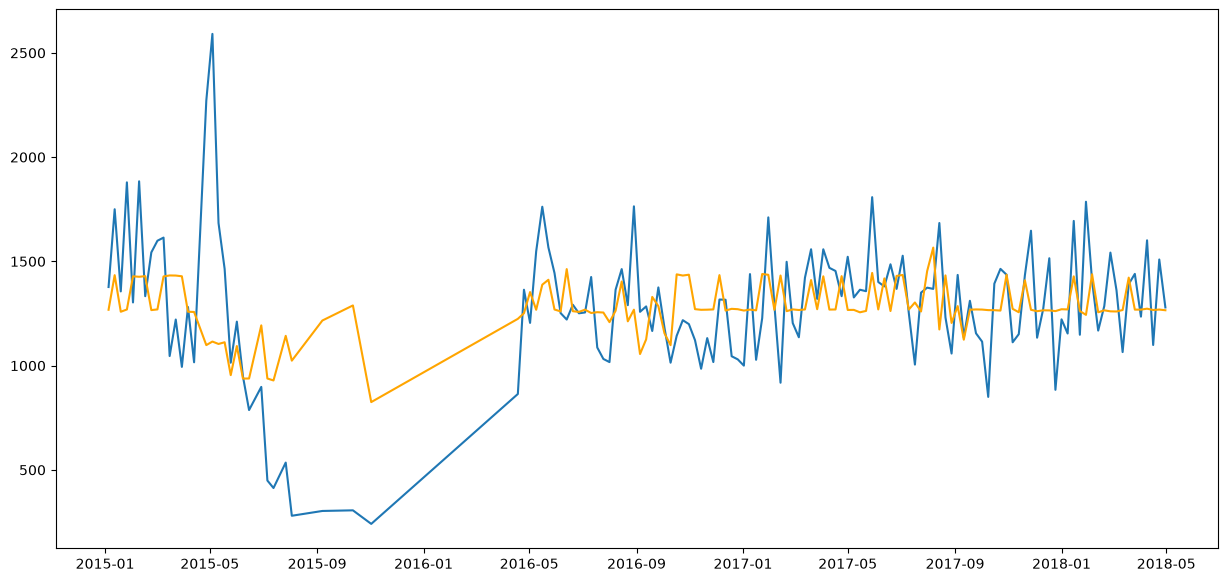

In [50]:
pyplot.plot(subset['Date'], subset['VolumePC_sum'])
pyplot.plot(subset['Date'], predictions, c='orange')


### Qualität der Vorhersage messen

In [51]:
sum(subset['VolumePC_sum'] - predictions)

-2.7484679776534904e-07

In [52]:
sum(abs(subset['VolumePC_sum'] - predictions))

30772.87214838998

### Durchschnittliche absolute Fehler (MAE):

In [53]:
sum(abs(subset['VolumePC_sum'] - predictions)) / subset.shape[0]

222.99182716224624

### Durchschnittliche absolute Fehler (MSE):

In [54]:
sum((subset['VolumePC_sum'] - predictions) ** 2) / subset.shape[0]

98537.02974307262

In [55]:
predictions

17      1267.896204
49      1433.932303
83      1258.411356
115     1269.252906
149     1428.324881
           ...     
5798    1268.584544
5834    1273.114077
5872    1266.681856
5911    1268.903263
5948    1265.623333
Length: 138, dtype: float64